# 6. Designing the pruning thresholds

Beyond acceleration and jerk, a grid search over all parameters is too
large. loki's EP (extreme pruning) search instead grows the phase model
one data segment at a time:

1. a P-FFA over short segments gives the starting folds;
2. at each **stage**, the next segment is added, every surviving
   parameter node branches into `B_s` finer children (the longer span
   resolves the parameters better), and each child is scored;
3. children scoring below the stage threshold `γ_s` are dropped.

The thresholds decide everything: too low and the tree explodes, too high
and the pulsar is pruned early, when its S/N is still small. The
schedule `γ_0 … γ_M` is a trade-off between **cost** (nodes scored) and
**detection probability** `P_d` (a pulsar of the design S/N surviving
every stage). `libloki.thresholds.DynamicThresholdScheme` finds a
schedule of low cost per detection subject to `P_d ≥ min_pd`, by
simulation; `docs/dts.md` describes the method.

This notebook designs the schedule for the circular-orbit search of
notebook 9 and compares it with simple alternatives.

Runtime: about 30 seconds; memory: about 3.5 GB.

In [1]:
%matplotlib inline
from dataclasses import dataclass
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt
from scipy import stats

from loki import libloki
from loki.libloki.configs import PulsarSearchConfig, circular_param_limits
from loki.libloki.plans import FFAPlanBase
from pyloki.detection import schemes, thresholding

libloki.set_log_level("warning")  # hide loki's per-step info messages
SEED = 1
NTHREADS = 4  # CPU threads; raise it on a machine of your own
OUTDIR = Path("_output")

## The branching pattern

The search of notebook 9: 2^24 samples of 64 µs (18 minutes),
142.5–143.5 Hz, a 5th-order phase model (frequency up to crackle) over
the circular orbits with `P_orb ≥ T_obs`, `m_c ≤ 10 M☉` and
`m_p ≥ 1.2 M☉`, and 128 segments, so 127 stages. The plan gives the
branching factor of every stage, and the number of starting trees (P-FFA
trials at the first segment).

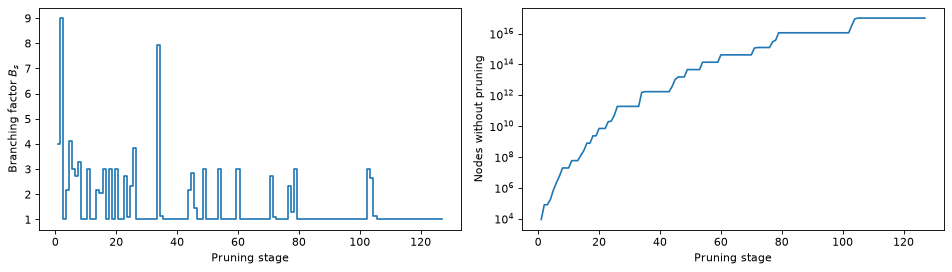

127 stages, 2217 starting trees, 1.01e+17 leaves without pruning


In [2]:
nsamps, tsamp = 2**24, 64e-6
p_orb_min, m_c_max, m_p_min = nsamps * tsamp, 10.0, 1.2
limits = circular_param_limits(
    142.5,
    143.5,
    poly_order=5,
    p_orb_min=p_orb_min,
    m_c_max=m_c_max,
    m_p_min=m_p_min,
)
search_cfg = PulsarSearchConfig(
    nsamps=nsamps,
    tsamp=tsamp,
    nbins=64,
    eta=1,
    param_limits=limits,
    bseg_brute=nsamps // 8192,
    nsegments=128,
    prune_poly_order=5,
    nthreads=NTHREADS,
    ducy_max=0.5,
    wtsp=1.2,
    use_fourier=True,
    p_orb_min=p_orb_min,
    m_c_max=m_c_max,
    m_p_min=m_p_min,
)
plan = FFAPlanBase(search_cfg)
branching_pattern = np.asarray(plan.get_branching_pattern(), dtype=np.float32)
n_trees = plan.ncoords[-1]
nstages = len(branching_pattern)
stage = np.arange(1, nstages + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5), dpi=80)
ax1.step(stage, branching_pattern, where="mid")
ax1.set_xlabel("Pruning stage")
ax1.set_ylabel("Branching factor $B_s$")
ax2.semilogy(stage, np.cumprod(branching_pattern) * n_trees)
ax2.set_xlabel("Pruning stage")
ax2.set_ylabel("Nodes without pruning")
plt.tight_layout()
plt.show()
print(
    f"{nstages} stages, {n_trees} starting trees, "
    f"{np.prod(branching_pattern.astype(np.float64)) * n_trees:.2e} "
    "leaves without pruning",
)

Most stages have `B_s = 1`: the new segment does not yet resolve a finer
grid, so the nodes just accumulate S/N. Without pruning the trees would
end with about 10^17 leaves in total; the search can afford a few
million.

**What S/N is significant?** The number of leaves sets the false-alarm
level. The S/N at which one false alarm is expected among all leaves of
one tree, of all trees, and of all trees in a search over 1000 such
frequency chunks:

In [3]:
log10_leaves = np.log10(np.prod(branching_pattern.astype(np.float64)))
for label, log10_trials in [
    ("one tree", log10_leaves),
    ("all trees", log10_leaves + np.log10(n_trees)),
    ("x 1000 chunks", log10_leaves + np.log10(n_trees) + 3),
]:
    print(f"{label:>14}: S/N {stats.norm.isf(10**-log10_trials):.2f}")

      one tree: S/N 7.55
     all trees: S/N 8.50
 x 1000 chunks: S/N 9.26


## Design

The design point: a pulsar of folded S/N 10 (`snr_final`, loki's default
`target_snr` for a search over five parameters), the pulse
shape of the simulations (`ref_ducy`, 64 bins), the search's boxcar
widths (`ducy_max`, `wtsp`), and `min_pd = 0.1`. A detection
probability of 0.1 per tree is enough because the EP search runs
independent trees from different reference segments (notebook 9); the
last section shows what that buys.

The scheme runs in its `improved` mode: `run()` searches the schedules
stage by stage, and `get_best_path_thresholds(min_pd)` returns the
cheapest one that reaches `min_pd`. The search's own `P_d` estimate is
optimistic (it picks the luckiest candidates), so the schedule is
evaluated again on fresh simulations below. `save()` writes every
explored path to an HDF5 file for later analysis.

In [4]:
target_snr, ref_ducy, nbins = search_cfg.target_snr, 0.1, 64
ducy_max, wtsp = search_cfg.ducy_max, search_cfg.wtsp

dts = libloki.thresholds.DynamicThresholdScheme(
    branching_pattern,
    ref_ducy,
    nbins,
    snr_final=target_snr,
    ducy_max=ducy_max,
    wtsp=wtsp,
    mode="improved",
    beam_width=2.0,
    nthreads=NTHREADS,
    seed=SEED,
)
dts.run(thres_neigh=10, show_progress=False)
dts_thresholds = np.asarray(dts.get_best_path_thresholds(min_pd=0.1), dtype=np.float32)
results_file = dts.save(outdir=str(OUTDIR))
print(
    f"{len(dts_thresholds)} thresholds, from {dts_thresholds[0]:.2f} to "
    f"{dts_thresholds[-1]:.2f}",
)

127 thresholds, from 2.10 to 7.60


Every path the scheme explored, one per final detection probability
(blue), and the cheapest one with `P_d ≥ 0.1` (red):
`DynamicThresholdSchemeAnalyser` reads the saved file, `plot_paths`
draws the paths and `backtrack_best` returns the cheapest path for each
requested `min_pd`.

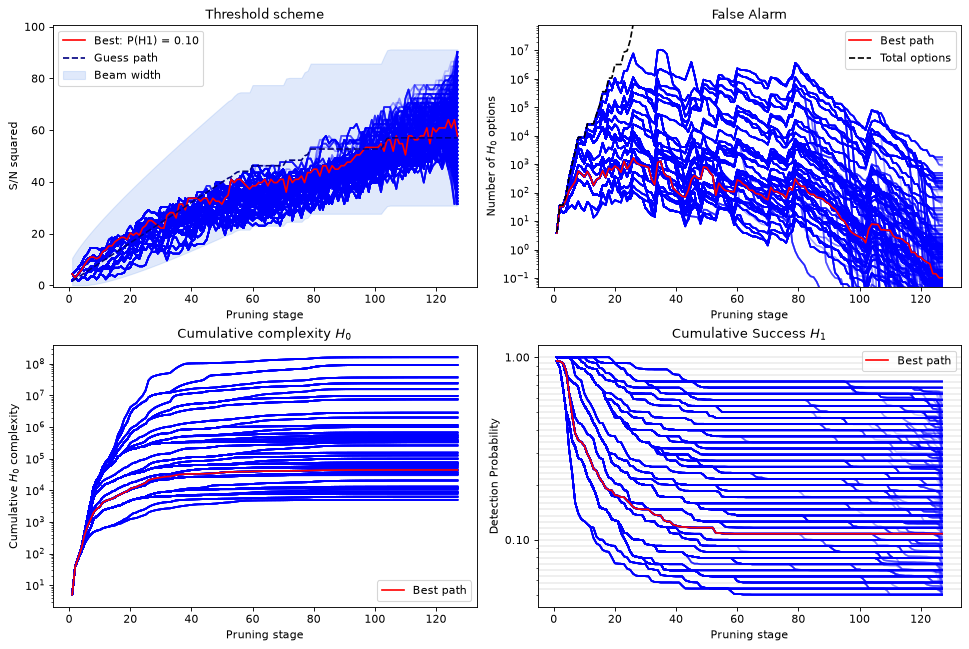

In [5]:
dts_paths = schemes.DynamicThresholdSchemeAnalyser.from_file(results_file)
fig, _ = dts_paths.plot_paths(best_prob=0.1, min_prob=0.001)
fig.set_dpi(80)
plt.show()

## Comparison with simple schedules

| schedule | rule |
|---|---|
| bound | S/N² grows linearly to `snr_final`: the expected S/N of the design signal after each stage |
| trials | one false alarm per stage among the nodes of one tree |
| min(bound, trials) | the lower of the two |
| constant survival | the noise survival fixed at `1 / B_s` per stage (the tree stops growing), all nodes kept for the first 15 stages |
| DTS (P_d ≥ 0.1) | the schedule designed above |
| DTS (P_d ≥ 0.3), DTS (P_d ≥ 0.5) | the cheapest explored paths with a higher `min_pd` |

Each is evaluated on 2^15 fresh simulated trials.

In [6]:
bound = schemes.bound_scheme(nstages, target_snr)
trials = schemes.trials_scheme(branching_pattern, 1)
survive = (1 / branching_pattern).astype(np.float32)
survive[:15] = 1
dts_03, dts_05 = dts_paths.backtrack_best(min_probs=[0.3, 0.5])
constant = libloki.thresholds.determine_scheme(
    survive,
    branching_pattern,
    ref_ducy,
    nbins,
    snr_final=target_snr,
    ducy_max=ducy_max,
    wtsp=wtsp,
    seed=SEED + 1,
)["threshold"]


@dataclass
class Schedule:
    name: str
    thresholds: np.ndarray
    color: str
    ls: str = "-"


candidates = [
    Schedule("bound", bound, "tab:orange"),
    Schedule("min(bound, trials)", np.minimum(bound, trials), "navy", "--"),
    Schedule("constant survival", constant, "tab:red"),
    Schedule("DTS (P_d ≥ 0.5)", dts_05.thresholds, "skyblue"),
    Schedule("DTS (P_d ≥ 0.3)", dts_03.thresholds, "dodgerblue"),
    Schedule("DTS (P_d ≥ 0.1)", dts_thresholds, "tab:blue"),
]
states = {
    s.name: libloki.thresholds.evaluate_scheme(
        np.asarray(s.thresholds, dtype=np.float32),
        branching_pattern,
        ref_ducy,
        nbins,
        ntrials=2**15,
        snr_final=target_snr,
        ducy_max=ducy_max,
        wtsp=wtsp,
        seed=SEED + 1,
    )
    for s in candidates
}

print(
    f"{'schedule':>20}  {'P_d':>6}  {'cost C':>9}  {'C / P_d':>9}  {'peak leaves':>11}",
)
for s in candidates:
    st = states[s.name]
    pd, cost = st["success_h1_cumul"][-1], st["complexity_cumul"][-1]
    peak = st["complexity"].max() * n_trees
    print(f"{s.name:>20}  {pd:6.3f}  {cost:9.3g}  {cost / pd:9.3g}  {peak:11.3g}")

            schedule     P_d     cost C    C / P_d  peak leaves
               bound   0.059   3.24e+05   5.49e+06     6.07e+07
  min(bound, trials)   0.147   3.25e+05   2.21e+06     6.07e+07
   constant survival   0.426   9.66e+06   2.27e+07     3.15e+08
     DTS (P_d ≥ 0.5)   0.454   8.57e+06   1.89e+07     7.88e+08
     DTS (P_d ≥ 0.3)   0.280   1.25e+06   4.46e+06     8.24e+07
     DTS (P_d ≥ 0.1)   0.082   5.51e+04    6.7e+05     5.55e+06


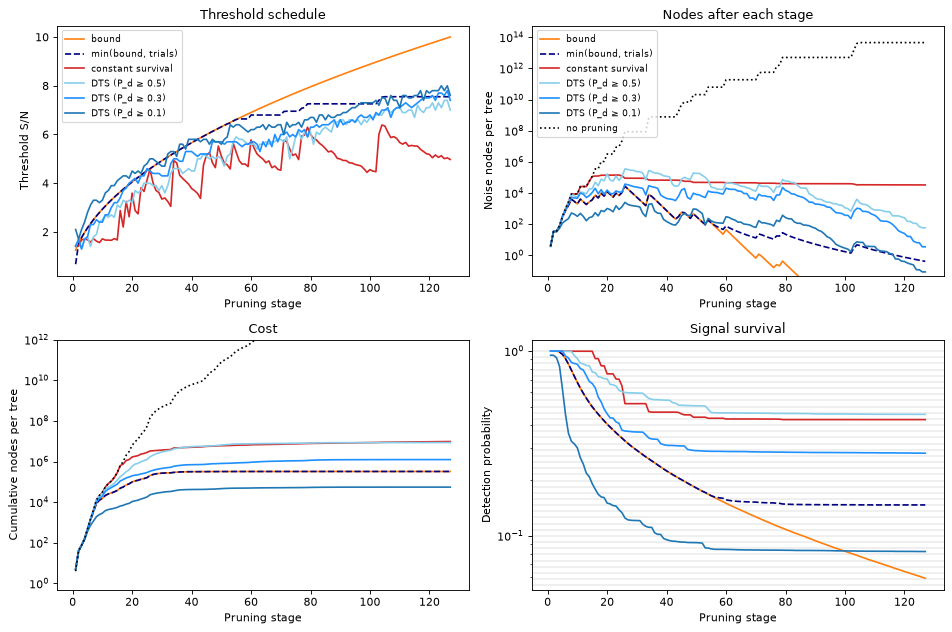

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), dpi=80)
panels = [
    ("threshold", "Threshold S/N", "Threshold schedule", False),
    ("complexity", "Noise nodes per tree", "Nodes after each stage", True),
    ("complexity_cumul", "Cumulative nodes per tree", "Cost", True),
    ("success_h1_cumul", "Detection probability", "Signal survival", True),
]
for ax, (field, ylabel, title, log) in zip(axes.flat, panels, strict=True):
    for s in candidates:
        ax.plot(stage, states[s.name][field], label=s.name, c=s.color, ls=s.ls)
    ax.set_xlabel("Pruning stage")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if log:
        ax.set_yscale("log")
axes[0, 1].plot(stage, np.cumprod(branching_pattern), c="k", ls=":", label="no pruning")
axes[0, 1].set_ylim(0.05, None)
axes[1, 0].plot(
    stage,
    np.cumsum(np.cumprod(branching_pattern)),
    c="k",
    ls=":",
    label="no pruning",
)
axes[1, 0].set_ylim(0.5, 1e12)
for pd in dts_paths.probs[1:]:
    axes[1, 1].axhline(pd, c="gray", alpha=0.15, zorder=0)
axes[0, 0].legend(fontsize="small")
axes[0, 1].legend(fontsize="small")
plt.tight_layout()
plt.show()

The designed schedule prunes hardest in the first ~30 stages: a node kept
there would branch many times later, so that is where the cost is
saved, and it is also where the schedule spends most of its
detection-probability budget. Later its thresholds fall below the bound,
so the signal that survived is not lost. The bound and min(bound,
trials) schedules prune little at first and score about six times more
nodes (the bound also ends well below `min_pd`, its thresholds keep
rising); constant survival keeps the pulsar more often but holds a large
tree throughout and costs about 150 times more. Asking the scheme for a
higher `min_pd` is expensive too: the cheapest paths with `P_d ≥ 0.3`
and `P_d ≥ 0.5` score about 25 and 190 times more nodes, and their trees
peak at 10^8 leaves or more, far beyond memory. Several independent runs
at `P_d ≈ 0.1` (last section) are the cheaper way to a high detection
probability.

On fresh trials the designed schedule delivers `P_d ≈ 0.08`, a little
below `min_pd = 0.1`: the improved mode ranks candidates on their own
simulations, so its in-run estimate is optimistic (`docs/dts.md`).

The summary of the designed schedule, from pyloki's own evaluation on
fresh trials: the branching pattern and the thresholds (rounded, ready
to paste), the costs in log2, and the survival probability over the
independent trees a search can run.

In [8]:
thresholding.evaluate_scheme(
    dts_thresholds,
    branching_pattern,
    ref_ducy,
    nbins,
    ntrials=2**12,
    snr_final=target_snr,
    ducy_max=ducy_max,
    wtsp=wtsp,
    seed=SEED,
).print_summary()

Branching Pattern: [4.0,9.0,1.0,2.2,4.1,3.0,2.7,3.3,1.0,1.0,3.0,1.0,1.0,2.2,2.1,3.0,1.0,3.0,
 1.0,3.0,1.0,1.0,2.7,1.1,2.3,3.8,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.9,1.1,1.0,
 1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.2,2.9,1.4,1.0,1.0,3.0,1.0,1.0,1.0,1.0,3.0,
 1.0,1.0,1.0,1.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.7,1.1,
 1.0,1.0,1.0,1.0,2.3,1.3,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,
 1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,2.6,1.1,1.0,1.0,1.0,
 1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,
 1.0]

Thresholds: [2.1,1.7,2.1,2.4,2.8,3.1,3.3,3.3,3.2,3.3,3.6,3.7,3.9,3.9,4.1,4.2,4.3,4.3,
 4.2,4.5,4.4,4.5,4.4,4.7,4.8,5.0,5.0,4.9,4.8,4.7,4.7,5.2,5.3,5.3,5.1,5.6,
 5.6,5.4,5.8,5.8,5.8,5.8,5.7,5.8,5.8,5.6,5.8,5.7,5.7,5.6,5.8,5.9,6.4,6.3,
 6.4,6.4,6.3,6.2,6.1,6.2,6.2,6.3,6.3,6.4,6.2,6.4,6.3,6.3,6.4,6.4,6.0,6.5,
 6.3,6.4,6.4,6.5,6.3,6.6,6.6,6.7,6.7,6.5,6.8,6.8,6.6,6.8,6.7,6.7,6.8,6.8,
 6.9,6.9,7.0,7.1,7.1,7.2,7.3,7.3,7.3,7.3,7.3,7.4,7.2,7.5,7.5,7.2,7.6,7.4,
 7.4,7.1,7.6,7.6,7.5,7.5,7.6,7.6,7.8,7.4,7.8,7.7,7.8,7.8,7.8,8.0,7.8,8.0,
 7.6]

         Scheme Metrics Summary         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Metric                       ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ Branching mean               │  1.28 │
│ Branching max                │  9.00 │
│ Total enumerated options     │ 45.38 │
│ Pruning complexity           │ 15.36 │
│ Crude survival probability   │  0.08 │
│ Total cost                   │ 19.04 │
│ Number of independent trials │ 16.71 │
│ Total survival probability   │  0.74 │
└──────────────────────────────┴───────┘

## Cost and memory

Left: the cost per detection after each stage (nodes scored so far over
the detection probability so far). Right: the search keeps the surviving
leaves of all trees of a run in memory. Notebook 9 caps them at
`max_sugg = 2^22`. Around stage 26 the expected tree is slightly larger;
the search then keeps the highest-scoring leaves.

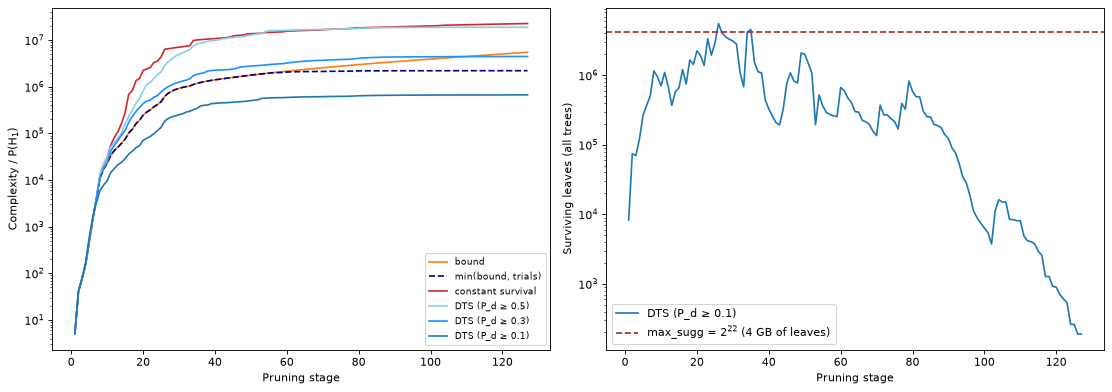

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=80)
for s in candidates:
    ax1.plot(stage, states[s.name]["cost"], label=s.name, c=s.color, ls=s.ls)
ax1.set_xlabel("Pruning stage")
ax1.set_ylabel("Complexity / P(H$_1$)")
ax1.set_yscale("log")
ax1.legend(fontsize="small")

max_sugg = 2**22
# Leaves are kept as complex folds of 2 x nbins values, 8 bytes each.
leaf_gb = max_sugg * 2 * nbins * 8 / 2**30
ax2.semilogy(
    stage,
    states["DTS (P_d ≥ 0.1)"]["complexity"] * n_trees,
    label="DTS (P_d ≥ 0.1)",
)
ax2.axhline(
    max_sugg,
    ls="--",
    c="brown",
    label=f"max_sugg = $2^{{22}}$ ({leaf_gb:.0f} GB of leaves)",
)
ax2.set_xlabel("Pruning stage")
ax2.set_ylabel("Surviving leaves (all trees)")
ax2.legend()
plt.tight_layout()
plt.show()

## Detection probability vs S/N and number of runs

The schedule is designed at S/N 10. The detection probability of a
pulsar of another S/N, for one run and for `n` independent runs (trees
started from different reference segments, `1 - (1 - P_d)^n`):

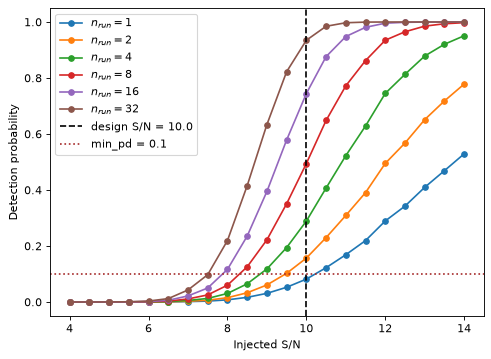

In [10]:
snr_inj = np.linspace(4, 14, 21)
pd_one = np.array(
    [
        libloki.thresholds.evaluate_scheme(
            dts_thresholds,
            branching_pattern,
            ref_ducy,
            nbins,
            ntrials=2**13,
            snr_final=snr,
            ducy_max=ducy_max,
            wtsp=wtsp,
            seed=SEED + 1,
        )["success_h1_cumul"][-1]
        for snr in snr_inj
    ],
)

fig, ax = plt.subplots(figsize=(7, 5), dpi=80)
for n_runs in (1, 2, 4, 8, 16, 32):
    ax.plot(
        snr_inj,
        1 - (1 - pd_one) ** n_runs,
        marker="o",
        ms=5,
        label=f"$n_{{run}} = {n_runs}$",
    )
ax.axvline(target_snr, ls="--", c="k", label=f"design S/N = {target_snr}")
ax.axhline(0.1, ls=":", c="brown", label="min_pd = 0.1")
ax.set_xlabel("Injected S/N")
ax.set_ylabel("Detection probability")
ax.legend()
plt.show()